In [1]:
!pip -q install diffusers

import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt

from torchvision.datasets import MNIST
from torch.utils.data import DataLoader, TensorDataset
from diffusers import UNet2DModel, DDPMScheduler

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Using:", device)

dataset = MNIST("./data", train=True, download=True)

images = dataset.data[:10000].unsqueeze(1).float() / 127.5 - 1

labels = dataset.targets[:len(images)]

conditional_dataset = TensorDataset(images, labels)

conditional_loader = DataLoader(
    conditional_dataset,
    batch_size=64,
    shuffle=True
)

Using: cuda


100%|██████████| 9.91M/9.91M [00:01<00:00, 5.39MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 129kB/s]
100%|██████████| 1.65M/1.65M [00:01<00:00, 1.24MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 3.58MB/s]


In [2]:
conditional_model = UNet2DModel(
    sample_size=28,
    in_channels=1,
    out_channels=1,
    layers_per_block=2,
    block_out_channels=(32, 64),
    down_block_types=("DownBlock2D", "AttnDownBlock2D"),
    up_block_types=("AttnUpBlock2D", "UpBlock2D"),
    norm_num_groups=8,
    num_class_embeds=10
).to(device)

conditional_scheduler = DDPMScheduler(num_train_timesteps=1000)

conditional_optimizer = torch.optim.Adam(conditional_model.parameters(), lr=1e-3)

In [3]:
for epoch in range(10):
    conditional_model.train()

    for clean_images, labels in conditional_loader:
        clean_images = clean_images.to(device)
        labels = labels.to(device)

        noise = torch.randn_like(clean_images)

        timesteps = torch.randint(0, 1000, (clean_images.shape[0],), device=device)

        noisy_images = conditional_scheduler.add_noise(clean_images, noise, timesteps)

        predicted_noise = conditional_model(
            noisy_images,
            timesteps,
            class_labels=labels
        ).sample

        loss = F.mse_loss(predicted_noise, noise)

        conditional_optimizer.zero_grad()
        loss.backward()
        conditional_optimizer.step()

    print("Epoch:", epoch + 1, "Last batch loss:", loss.item())

Epoch: 1 Last batch loss: 0.03478096425533295
Epoch: 2 Last batch loss: 0.02862008474767208
Epoch: 3 Last batch loss: 0.04316484555602074
Epoch: 4 Last batch loss: 0.029203297570347786
Epoch: 5 Last batch loss: 0.029359742999076843
Epoch: 6 Last batch loss: 0.022005701437592506
Epoch: 7 Last batch loss: 0.018263688310980797
Epoch: 8 Last batch loss: 0.03212476521730423
Epoch: 9 Last batch loss: 0.01836697943508625
Epoch: 10 Last batch loss: 0.0301472470164299


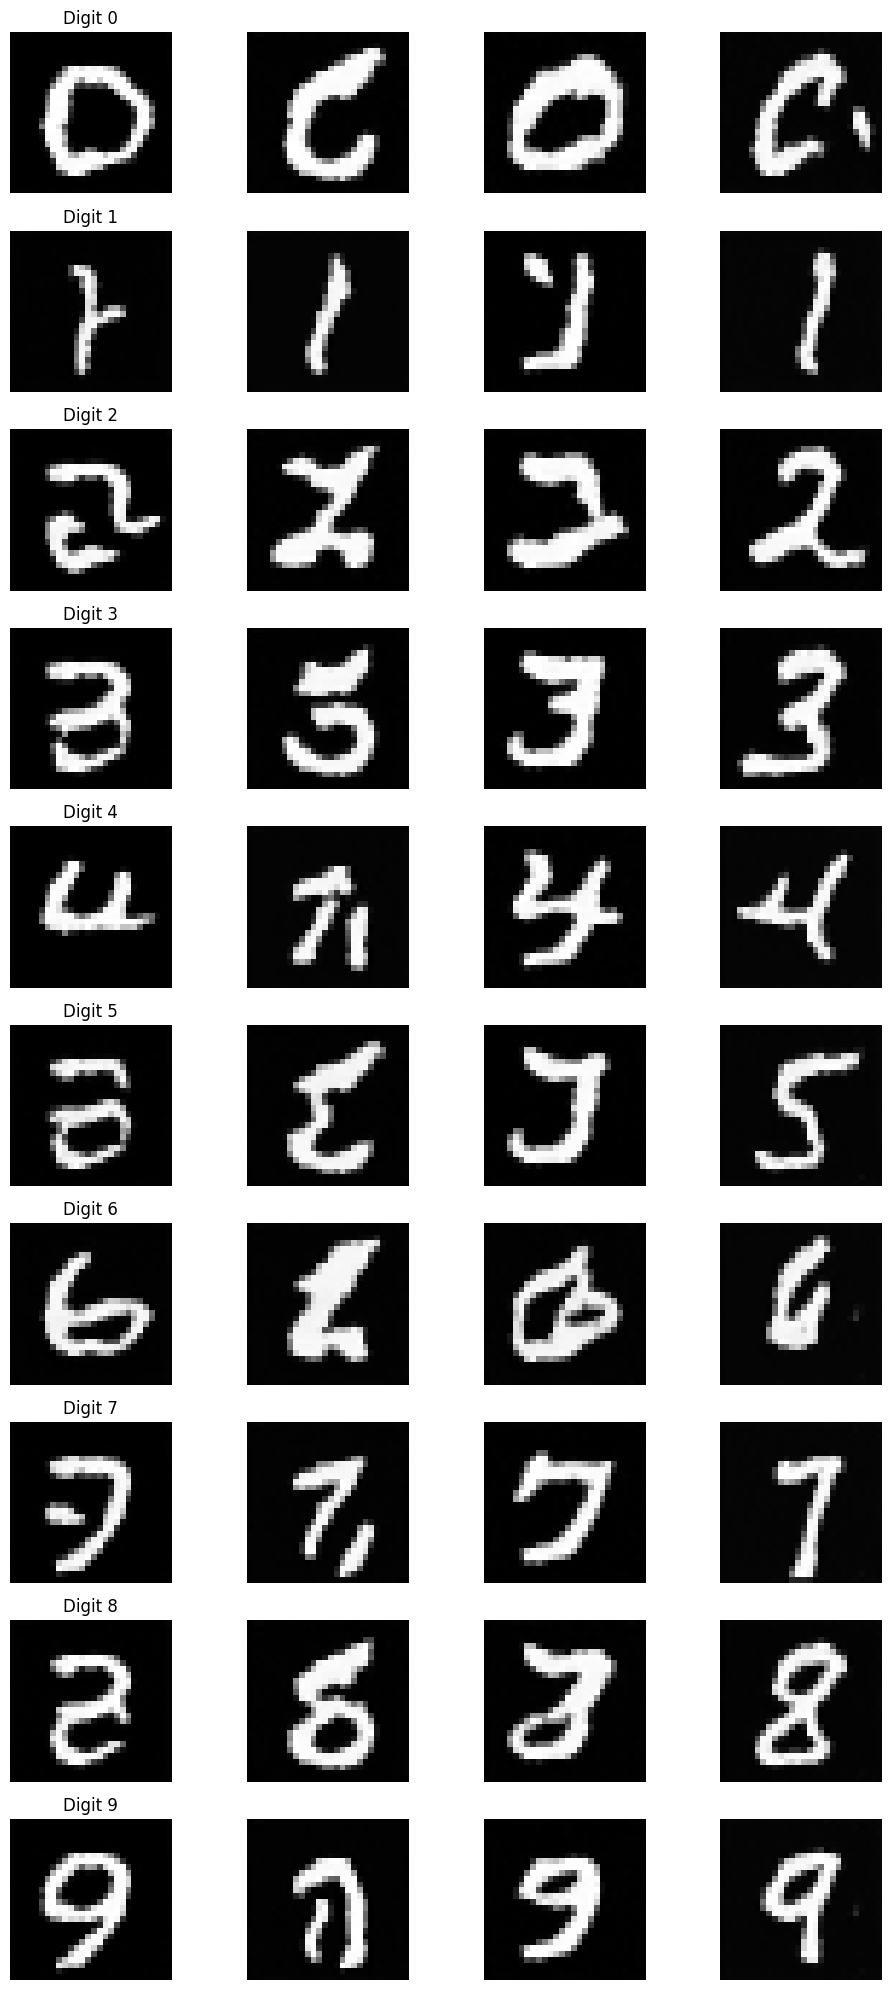

In [6]:
digits = list(range(10))

conditional_model.eval()
conditional_scheduler.set_timesteps(100)

fig, axes = plt.subplots(10, 4, figsize=(10, 20))

for row, digit in enumerate(digits):
    torch.manual_seed(42)
    sample = torch.randn(4, 1, 28, 28, device=device)
    labels = torch.full((4,), digit, dtype=torch.long, device=device)

    with torch.no_grad():
        for t in conditional_scheduler.timesteps:
            predicted_noise = conditional_model(sample, t, class_labels=labels).sample
            sample = conditional_scheduler.step(predicted_noise, t, sample).prev_sample

    for col in range(4):
        image = ((sample[col, 0] + 1) / 2).clamp(0, 1)
        axes[row, col].imshow(image.cpu(), cmap="gray", vmin=0, vmax=1)
        axes[row, col].axis("off")

    axes[row, 0].set_title(f"Digit {digit}")

plt.tight_layout()
plt.show()